In [ ]:
# STEP 1: Load original KDD Train/Test files

import pandas as pd

TRAIN_PATH = "KDDTrain+.txt"
TEST_PATH  = "KDDTest+.txt"

# Column names for the NSL-KDD dataset (41 features + label + difficulty level)
cols = [
 'duration','protocol_type','service','flag','src_bytes','dst_bytes','land','wrong_fragment','urgent',
 'hot','num_failed_logins','logged_in','num_compromised','root_shell','su_attempted','num_root',
 'num_file_creations','num_shells','num_access_files','num_outbound_cmds','is_host_login','is_guest_login',
 'count','srv_count','serror_rate','srv_serror_rate','rerror_rate','srv_rerror_rate','same_srv_rate',
 'diff_srv_rate','srv_diff_host_rate','dst_host_count','dst_host_srv_count','dst_host_same_srv_rate',
 'dst_host_diff_srv_rate','dst_host_same_src_port_rate','dst_host_srv_diff_host_rate','dst_host_serror_rate',
 'dst_host_srv_serror_rate','dst_host_rerror_rate','dst_host_srv_rerror_rate','label','difficulty_level'
]

# Load the datasets using the predefined column names
train = pd.read_csv(TRAIN_PATH, names=cols)
test = pd.read_csv(TEST_PATH, names=cols)

# Convert labels to binary target: 1 = attack, 0 = normal
train["target"] = (train["label"] != "normal").astype(int)
test["target"] = (test["label"] != "normal").astype(int)

# Drop original label and difficulty_level (not needed for training)
train = train.drop(columns=["label", "difficulty_level"])
test = test.drop(columns=["label", "difficulty_level"])

# Separate features (X) from the binary target (y) for training and testing
X_train = train.drop(columns=["target"])
y_train = train["target"]

X_test = test.drop(columns=["target"])
y_test = test["target"]

# Display dataset shapes and target distribution for verification
print("Dataset loaded with correct separation ✅")
print("Train shape:", X_train.shape)
print("Test shape: ", X_test.shape)
print("Target distribution in train:\n", y_train.value_counts())
print("Target distribution in test:\n", y_test.value_counts())


Dataset loaded with correct separation ✅
Train shape: (125973, 41)
Test shape:  (22544, 41)
Target distribution in train:
 target
0    67343
1    58630
Name: count, dtype: int64
Target distribution in test:
 target
1    12833
0     9711
Name: count, dtype: int64


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Identify categorical and numerical columns
# (NSL-KDD has 3 categorical features, the rest are numerical)
cat_cols = ["protocol_type", "service", "flag"]
num_cols = [c for c in X_train.columns if c not in cat_cols]

# Numerical preprocessing pipeline:
# - Impute missing values using the median
# - Standardize numerical features to zero mean / unit variance
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing pipeline:
# - Impute missing values with the most frequent category
# - One-hot encode categorical variables
# - ignore unknown categories at test time to avoid errors
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numerical and categorical preprocessing into a single transformer
# This ensures consistent preprocessing during training and evaluation
preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

print("Preprocessing pipeline ready ✅")


Preprocessing pipeline ready ✅


In [ ]:
from sklearn.model_selection import StratifiedKFold

# Define 5-fold cross-validation with stratification:
# - StratifiedKFold preserves the class distribution in each fold
# - shuffle=True ensures randomized splitting
# - random_state provides reproducibility
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Create a pipeline that applies preprocessing first, then fits a Random Forest classifier
rf_pipe = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

# Hyperparameter grid for Random Forest:
# - n_estimators: number of trees in the forest
# - max_depth: maximum depth of each tree (None = grow until pure)
# - min_samples_leaf: minimum number of samples in a terminal leaf
rf_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 20],
    "model__min_samples_leaf": [1, 5]
}

# GridSearchCV for hyperparameter tuning:
# - evaluates all parameter combinations using cross-validation
# - scoring uses ROC-AUC (suitable for binary classification)
# - n_jobs=-1 uses all available CPU cores for faster training
rf_cv = GridSearchCV(
    rf_pipe,
    rf_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

# Fit the tuned Random Forest model on the training data
rf_cv.fit(X_train, y_train)

# Display best hyperparameters and best cross-validation score
print("Random Forest tuned ✅")
print("Best params:", rf_cv.best_params_)
print("Best CV score:", rf_cv.best_score_)


Random Forest tuned ✅
Best params: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Best CV score: 0.9999931673246774


In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV

# Pipeline for Naïve Bayes:
# - Apply preprocessing (imputation, scaling, one-hot encoding)
# - Train a Gaussian Naïve Bayes classifier
nb_pipe = Pipeline([
    ("preprocess", preprocessor),
    ("model", GaussianNB())
])

# Hyperparameter grid for GaussianNB:
# - var_smoothing controls numerical stability by adding a small value to variances
nb_grid = {
    "model__var_smoothing": [1e-12, 1e-10, 1e-9, 1e-8]
}

# Perform cross-validated hyperparameter tuning:
# - Uses ROC-AUC for evaluation
# - n_jobs = -1 enables parallel computation
nb_cv = GridSearchCV(
    nb_pipe,
    nb_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

# Fit Naïve Bayes on the training set with tuned parameters
nb_cv.fit(X_train, y_train)

# Output best hyperparameters and cross-validation performance
print("Naive Bayes tuned ✅")
print("Best params:", nb_cv.best_params_)
print("Best CV score:", nb_cv.best_score_)


Naive Bayes tuned ✅
Best params: {'model__var_smoothing': 1e-10}
Best CV score: 0.9798199366233049


In [ ]:
from sklearn.linear_model import LogisticRegression

# Pipeline for Logistic Regression:
# - Apply preprocessing (scaling + one-hot encoding)
# - Train a Logistic Regression classifier with max_iter increased for convergence
lr_pipe = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

# Hyperparameter grid:
# - C controls regularization strength (lower C = stronger regularization)
# - class_weight balances classes in case of imbalance
lr_grid = {
    "model__C": [0.1, 1.0, 10.0],
    "model__class_weight": [None, "balanced"]
}

# GridSearchCV for tuning Logistic Regression:
# - uses ROC-AUC as evaluation metric
# - 5-fold stratified CV
# - parallelized with n_jobs = -1
lr_cv = GridSearchCV(
    lr_pipe,
    lr_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

# Train the tuned Logistic Regression model
lr_cv.fit(X_train, y_train)

# Print best hyperparameters and best CV performance
print("Logistic Regression tuned ✅")
print("Best params:", lr_cv.best_params_)
print("Best CV score:", lr_cv.best_score_)


Logistic Regression tuned ✅
Best params: {'model__C': 10.0, 'model__class_weight': 'balanced'}
Best CV score: 0.9964606648125137


In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Pipeline for Decision Tree:
# - Apply preprocessing pipeline
# - Train a Decision Tree classifier
dt_pipe = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

# Hyperparameter grid for Decision Tree:
# - max_depth: limits the depth of the tree (None = fully grown tree)
# - min_samples_leaf: minimum number of samples required at a leaf node
#   (higher values reduce overfitting)
dt_grid = {
    "model__max_depth": [None, 10, 20],
    "model__min_samples_leaf": [1, 5, 10]
}

# GridSearchCV for hyperparameter tuning:
# - Tests all parameter combinations using stratified 5-fold CV
# - Uses ROC-AUC as the scoring metric
# - n_jobs = -1 allows parallel CPU usage
dt_cv = GridSearchCV(
    dt_pipe,
    dt_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

# Train the tuned Decision Tree model
dt_cv.fit(X_train, y_train)

# Print selected hyperparameters and best CV score
print("Decision Tree tuned ✅")
print("Best params:", dt_cv.best_params_)
print("Best CV score:", dt_cv.best_score_)


Decision Tree tuned ✅
Best params: {'model__max_depth': 20, 'model__min_samples_leaf': 10}
Best CV score: 0.9993120152560158


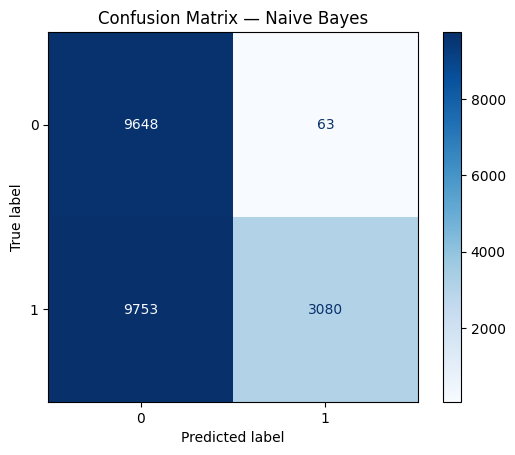

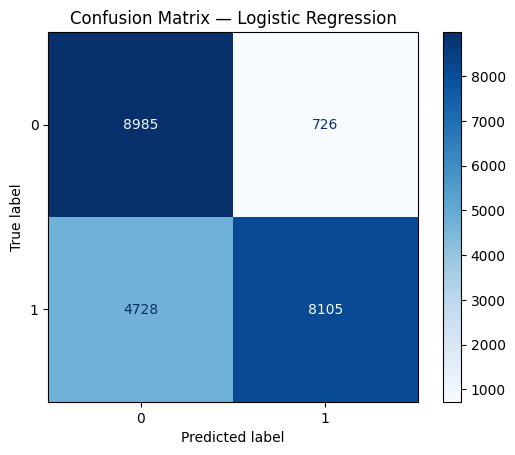

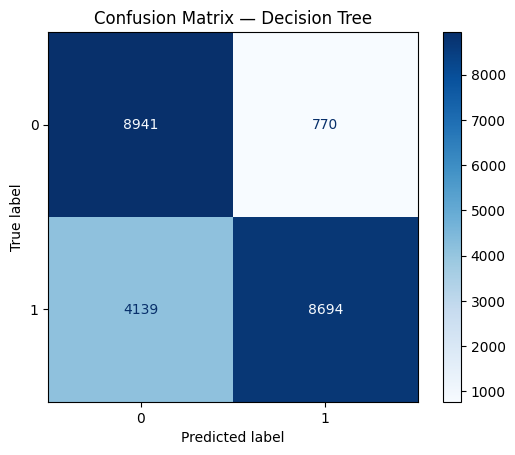

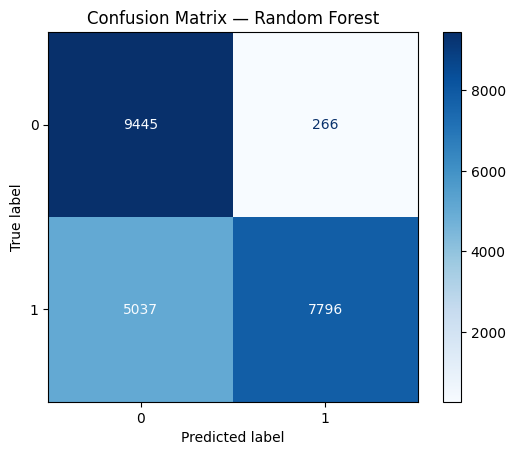

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Dictionary of the best models after hyperparameter tuning
models = {
    "Naive Bayes": nb_cv.best_estimator_,
    "Logistic Regression": lr_cv.best_estimator_,
    "Decision Tree": dt_cv.best_estimator_,
    "Random Forest": rf_cv.best_estimator_
}

# Generate confusion matrices for each model on the test set
for name, model in models.items():
    # Predict class labels on the test data
    y_pred = model.predict(X_test)

    # Display the confusion matrix
    disp = ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        cmap="Blues"
    )

    # Title for clarity
    plt.title(f"Confusion Matrix — {name}")
    plt.show()


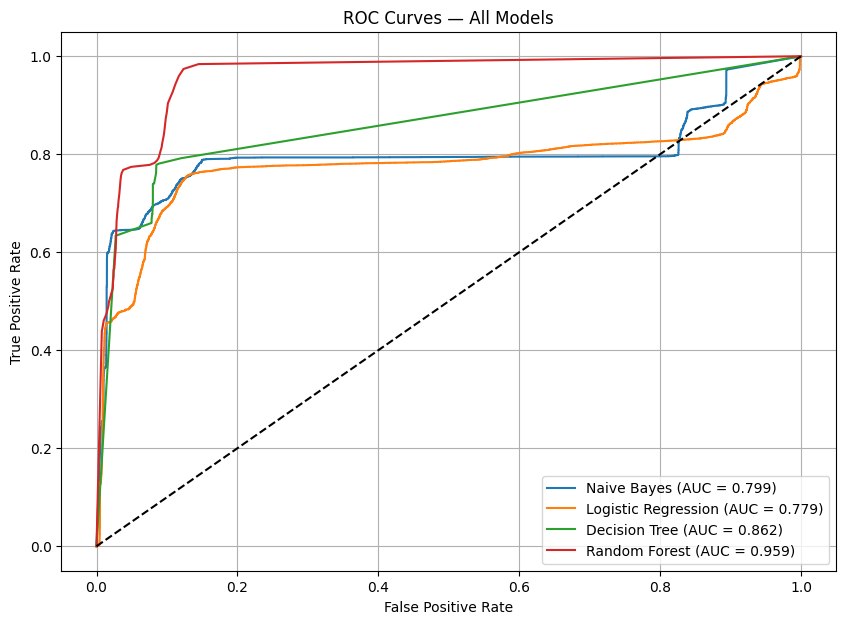

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

# Create a figure for plotting ROC curves
plt.figure(figsize=(10,7))

# Plot ROC curve for each tuned model
for name, model in models.items():
    # Predict probabilities for the positive class (attack = 1)
    y_proba = model.predict_proba(X_test)[:,1]

    # Compute ROC-AUC score
    auc = roc_auc_score(y_test, y_proba)

    # Compute false positive rate (FPR) and true positive rate (TPR)
    fpr, tpr, _ = roc_curve(y_test, y_proba)

    # Plot the ROC curve with AUC in the label
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

# Plot the diagonal reference line (random classifier)
plt.plot([0,1], [0,1], 'k--')

# Plot formatting
plt.title("ROC Curves — All Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
from sklearn.metrics import classification_report, accuracy_score

# Print accuracy and full classification report for each model
for name, model in models.items():
    print(f"\n==================== {name} ====================")

    # Predict class labels on the test set
    y_pred = model.predict(X_test)

    # Display overall accuracy
    print("Accuracy:", accuracy_score(y_test, y_pred))

    # Display precision, recall, and F1-score for each class
    print(classification_report(y_test, y_pred))



==================== Naive Bayes ====================
Accuracy: 0.5645848119233499
              precision    recall  f1-score   support

           0       0.50      0.99      0.66      9711
           1       0.98      0.24      0.39     12833

    accuracy                           0.56     22544
   macro avg       0.74      0.62      0.52     22544
weighted avg       0.77      0.56      0.51     22544


==================== Logistic Regression ====================
Accuracy: 0.7580731014904187
              precision    recall  f1-score   support

           0       0.66      0.93      0.77      9711
           1       0.92      0.63      0.75     12833

    accuracy                           0.76     22544
   macro avg       0.79      0.78      0.76     22544
weighted avg       0.80      0.76      0.76     22544


==================== Decision Tree ====================
Accuracy: 0.7822480482611781
              precision    recall  f1-score   support

           0       0.68      

In [ ]:
# Create a comparison table summarizing model performance
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Naive Bayes",
        "Random Forest"
    ],

    # Best cross-validation score (ROC-AUC) found during GridSearchCV
    "Best CV Score": [
        lr_cv.best_score_,
        dt_cv.best_score_,
        nb_cv.best_score_,
        rf_cv.best_score_
    ],

    # Test set accuracy for each best estimator
    "Test Accuracy": [
        accuracy_score(y_test, lr_cv.best_estimator_.predict(X_test)),
        accuracy_score(y_test, dt_cv.best_estimator_.predict(X_test)),
        accuracy_score(y_test, nb_cv.best_estimator_.predict(X_test)),
        accuracy_score(y_test, rf_cv.best_estimator_.predict(X_test)),
    ]
})

# Display the final comparison dataframe
comparison


,Model,Best CV Score,Test Accuracy
0,Logistic Regression,0.996461,0.758073
1,Decision Tree,0.999312,0.782248
2,Naive Bayes,0.979820,0.564585
3,Random Forest,0.999993,0.764771
